# Лабораторная работа 4. Бинарная классификация

Цель: на данных о кредитном дефолте построить три модели бинарной классификации — логистическую регрессию, SVM и CART — и сравнить их качество.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
)



## 1. Данные

Набор Bankloan: по клиенту известны возраст, образование, стаж, срок проживания по адресу, доход и долговая нагрузка. Целевая переменная `default` бинарная: 1 — дефолт, 0 — нет.

В признаках пропусков нет. У `default` пусто 450 строк из 1150: это объекты без метки, их нельзя ни обучать, ни проверять. `dropna()` оставляет 700 размеченных наблюдений. Деление стратифицированное, 30 % — test, чтобы в обеих частях сохранилась доля дефолтов (около 26 %).

In [2]:
df = pd.read_csv('Bank Loan Defaulter/Bankloan.csv')

print(df.info())
print(df.head())

labeled = df.dropna()
train, test = train_test_split(
    labeled, test_size=0.3, random_state=42, stratify=labeled['default']
)

train_X = train.drop(columns=['default'])
train_y = train['default']
test_X = test.drop(columns=['default'])
test_y = test['default']

print('Целевая переменная: default')
print('Признаки:', list(train_X.columns))
print('Размеченных строк:', len(labeled))
print('Train:', train_y.value_counts().to_dict())
print('Test:', test_y.value_counts().to_dict())

<class 'pandas.DataFrame'>
RangeIndex: 1150 entries, 0 to 1149
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1150 non-null   int64  
 1   ed        1150 non-null   int64  
 2   employ    1150 non-null   int64  
 3   address   1150 non-null   int64  
 4   income    1150 non-null   int64  
 5   debtinc   1150 non-null   float64
 6   creddebt  1150 non-null   float64
 7   othdebt   1150 non-null   float64
 8   default   700 non-null    float64
dtypes: float64(4), int64(5)
memory usage: 81.0 KB
None
   age  ed  employ  address  income  debtinc   creddebt   othdebt  default
0   41   3      17       12     176      9.3  11.359392  5.008608      1.0
1   27   1      10        6      31     17.3   1.362202  4.000798      0.0
2   40   1      15       14      55      5.5   0.856075  2.168925      0.0
3   41   1      15       14     120      2.9   2.658720  0.821280      0.0
4   24   2       2        0      28     17.3 

## 2. Выбросы

Ящики с усами строятся по обучающей выборке. Точки выше верхнего уса — кандидаты в выбросы.

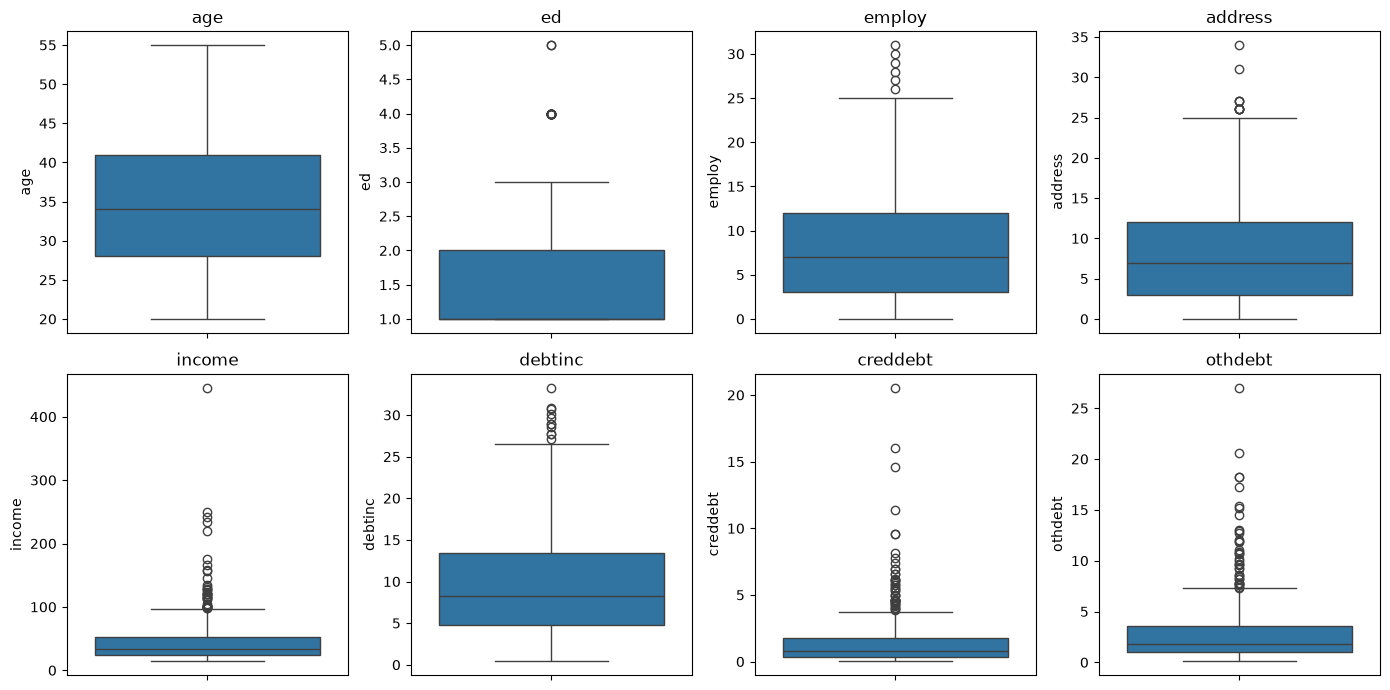

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, col in zip(axes.ravel(), train_X.columns):
    sns.boxplot(y=train_X[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 3. Что сделано с данными

В признаках пропусков нет. У `default` пусты 450 строк — это наблюдения без метки, их убрали до разбиения.

Точки за усами есть у `income`, `creddebt`, `othdebt` и у редких уровней `ed`. Это не ошибки записи: высокий доход и большой долг — реальные клиенты, а уровни образования 4 и 5 просто встречаются реже. Такие точки сильнее связаны с дефолтом, поэтому выбросы не удалялись.

Логистическая регрессия и SVM чувствительны к масштабу признаков. `StandardScaler` обучается только на train и тем же преобразованием применяется к test. Дерево CART от масштаба не зависит, его обучаем на исходных признаках.

In [4]:
scaler = StandardScaler()
train_X_scaled = scaler.fit_transform(train_X)
test_X_scaled = scaler.transform(test_X)

## 4. Модели

Три модели из задания: логистическая регрессия, SVM с ядром RBF и дерево решений CART. Дерево без ограничения глубины запоминает train (accuracy на обучении равна 1), поэтому для CART глубина ограничена 4.

Класс дефолта реже (около 26 %), поэтому одной accuracy мало. Для каждой модели считаются precision, recall, F1 и ROC-AUC по классу «дефолт».

In [5]:
models = {
    'Логистическая регрессия': (
        LogisticRegression(max_iter=1000),
        train_X_scaled,
        test_X_scaled,
    ),
    'SVM': (
        SVC(kernel='rbf'),
        train_X_scaled,
        test_X_scaled,
    ),
    'CART': (
        DecisionTreeClassifier(max_depth=4, random_state=42),
        train_X,
        test_X,
    ),
}

rows = []
preds = {}
for name, (model, X_tr, X_te) in models.items():
    model.fit(X_tr, train_y)
    pred = model.predict(X_te)
    if hasattr(model, 'predict_proba'):
        score = model.predict_proba(X_te)[:, 1]
    else:
        score = model.decision_function(X_te)
    preds[name] = pred
    rows.append({
        'Модель': name,
        'Accuracy': accuracy_score(test_y, pred),
        'Precision': precision_score(test_y, pred),
        'Recall': recall_score(test_y, pred),
        'F1': f1_score(test_y, pred),
        'ROC-AUC': roc_auc_score(test_y, score),
    })

metrics = pd.DataFrame(rows).set_index('Модель')
print(metrics.round(3))

                         Accuracy  Precision  Recall     F1  ROC-AUC
Модель                                                              
Логистическая регрессия     0.819      0.660   0.636  0.648    0.870
SVM                         0.781      0.622   0.418  0.500    0.818
CART                        0.800      0.623   0.600  0.611    0.805


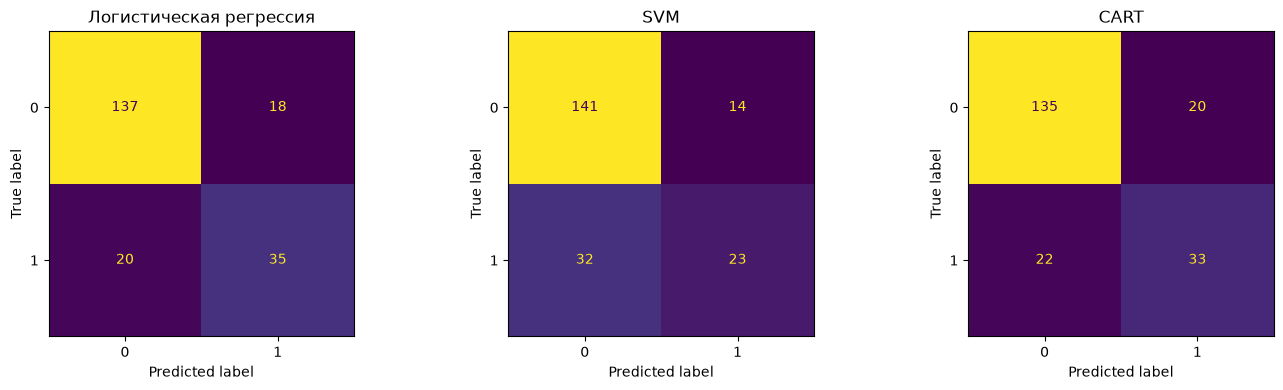

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay.from_predictions(
        test_y, pred, ax=ax, colorbar=False, display_labels=['0', '1']
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 5. Вывод

Лучше всего отделяет дефолт логистическая регрессия: ROC-AUC около 0.87, F1 около 0.65, accuracy 0.82. Из 55 дефолтов в test она находит 35 и ошибается на 18 благополучных клиентах.

SVM даёт близкую accuracy (0.78), но плохо находит дефолт: recall около 0.42. CART с глубиной 4 близок к логистической регрессии по F1 (около 0.61), AUC ниже (около 0.81). Без ограничения глубины дерево запоминает train и на test слабее.

Доля пропущенных дефолтов всё ещё заметна: класс 1 встречается реже. Если важнее не пропустить дефолт, модели можно обучить с `class_weight='balanced'` — recall вырастет, precision упадёт.